# Repair and complete rescheduling

The planning tool during execution (`math/05_rescheduling-frozen-part.md`) and the metrics of a run
(`math/23_metrics.md`).

In [ ]:
%matplotlib inline
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

import simulation
from simulation.io.brandimarte_loader import load_fjs
from simulation.io.json_loader import read_model
from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.planners.cpsat import solve
from simulation.planners.dispatching import best_dispatch, dispatch
from simulation.sim.scenario import sample_scenario
from simulation.viz import plot_gantt

DATA = Path(simulation.__file__).parents[2] / "data"
paths = sorted((DATA / "benchmarks" / "brandimarte").glob("*.fjs"), key=lambda p: int(p.stem.removeprefix("BrandimarteMk")))
toy_instance = read_model(DATA / "instances" / "toy-dag-3x4.json", Instance)
toy = compile_instance(toy_instance)
mk01 = compile_instance(load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs"))


def makespan(schedule):
    return max(a.end for a in schedule)

## Repair and complete rescheduling

The DES is the factory and only executes the plan last sent to it; changing the plan is the job of the planning tool
(`simulation.control.rescheduling.execute`, `math/05_rescheduling-frozen-part.md`). At every time point, after the
events are processed:

1. **Repair** (shift repair): left/right shift of the current plan, machines and order per machine kept;
   tight operations follow their blocker, planned gaps are kept.
2. **Complete rescheduling** if the repaired plan deviates from the **anchor** (the plan of the last complete
   rescheduling, at first the start plan) by more than $\delta_C$ in projected makespan or $\delta_S$ in any start
   time, so that small deviations add up instead of drifting below the threshold: a planner (dispatching rules or CP-SAT) builds a new plan for everything not
   started yet from the snapshot. It is accepted iff it changes at most $\kappa$ machine assignments (change budget;
   for CP-SAT the budget is a constraint).

Start offsets: a late worker delays the start relative to the moment the operation could actually start
(`math/13_des.md`, section 3), with and without repair.

### Toy case: weak plan, b1 runs long

Plan SPT + least load (makespan 15), b1 takes 1.5 × its planned time. Thresholds $\delta_C = 0$ (reschedule whenever
the projected makespan changes); rule planner SPT + ECT, CP-SAT planner 5 s.

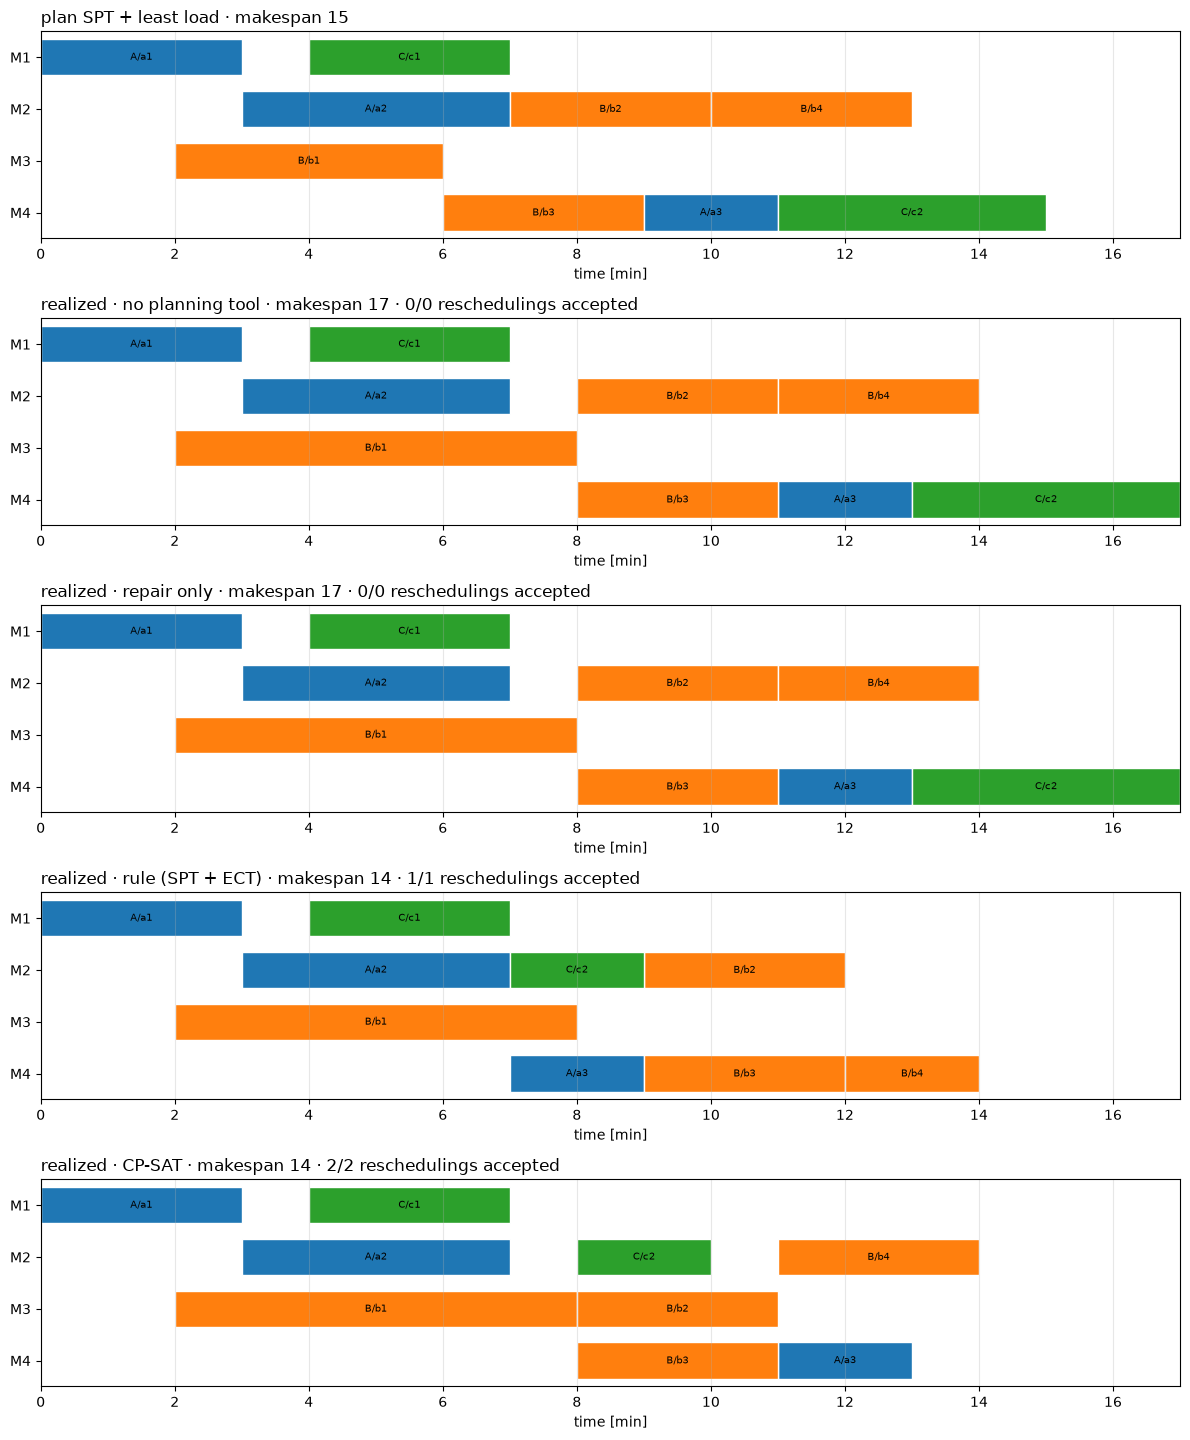

In [19]:
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.planners.cpsat import cpsat_planner
from simulation.planners.dispatching import dispatch_planner, ect, least_load, spt
from simulation.sim.scenario import Scenario


def toy_scenario(factor):
    return Scenario(instance=toy.name, seed=0, sigma=0, factors=[
        {"order_id": o.id, "op_id": op.id, "factor": factor.get(op.id, 1.0)}
        for o in toy_instance.orders for op in o.operations])


weak_plan = dispatch(toy, spt, least_load)
b1_long = toy_scenario({"b1": 1.5})
policies = {
    "no planning tool": None,
    "repair only": ReschedulingPolicy(),
    "rule (SPT + ECT)": ReschedulingPolicy(dispatch_planner(spt, ect), max_makespan_change=0),
    "CP-SAT": ReschedulingPolicy(cpsat_planner(time_limit=5), max_makespan_change=0),
}
toy_runs = {name: execute(toy, weak_plan, b1_long, policy) for name, policy in policies.items()}

fig, axes = plt.subplots(len(toy_runs) + 1, 1, figsize=(12, (len(toy_runs) + 1) * (0.45 * toy.n_machines + 1.1)))
plot_gantt(toy, weak_plan, ax=axes[0], title=f"plan SPT + least load · makespan {makespan(weak_plan)}")
for ax, (name, result) in zip(axes[1:], toy_runs.items()):
    replans = [d for d in result.decisions if d["type"] == "REPLAN"]
    plot_gantt(toy, result.schedule, ax=ax, title=f"realized · {name} · makespan {makespan(result.schedule)}"
               f" · {sum(d['accepted'] for d in replans)}/{len(replans)} reschedulings accepted")
xmax = max(ax.get_xlim()[1] for ax in axes)
for ax in axes:
    ax.set_xlim(right=xmax)
fig.tight_layout()

In [20]:
for d in toy_runs["rule (SPT + ECT)"].decisions:
    print(d)

{'t': 6, 'type': 'REPAIR', 'makespan_change': 1, 'max_shift': 1, 'makespan_deviation': 1, 'shift_deviation': 1}
{'t': 6, 'type': 'REPLAN', 'accepted': True, 'changed_assignments': 2, 'makespan_before': 16, 'makespan_after': 14, 'planner_time': 0.00015669999993406236}
{'t': 7, 'type': 'REPAIR', 'makespan_change': 0, 'max_shift': 0, 'makespan_deviation': 0, 'shift_deviation': 0}


### Change budget (CP-SAT)

Same case, CP-SAT with at most $\kappa$ changed machine assignments per rescheduling (hand-checked values in
`math/12_cp-sat.md`, section 7).

In [21]:
print(f"{'kappa':>10} {'makespan':>9} {'changed per rescheduling':>26}")
print(f"{'repair':>10} {makespan(toy_runs['repair only'].schedule):>9}")
for budget in (0, 1, 2, None):
    result = execute(toy, weak_plan, b1_long,
                     ReschedulingPolicy(cpsat_planner(time_limit=5, change_budget=budget), max_makespan_change=0))
    changed = [d["changed_assignments"] for d in result.decisions if d["type"] == "REPLAN"]
    print(f"{str(budget):>10} {makespan(result.schedule):>9} {str(changed):>26}")

     kappa  makespan   changed per rescheduling
    repair        17
         0        16                     [0, 0]
         1        15                     [1, 0]
         2        14                     [2, 0]
      None        14                     [2, 0]


### mk01 over 10 scenarios

Two disturbance settings, seeds 0–9 each: durations only ($\sigma = 0.3$), and durations plus start offsets
($q = 0.5$, $a = b = 5$). Two starting plans: the best dispatching
plan and a CP-SAT plan (warm start, 5 s). Policies: no planning tool, repair only, and complete rescheduling with the
rule planner (SPT + ECT) or CP-SAT (0.5 s per call, unbounded and with $\kappa = 5$). Rescheduling is triggered with
$\delta_C = 2, \delta_S = 10$ and with $\delta_C = 0$. Metrics from `simulation.metrics.run_metrics`
(`math/23_metrics.md`), means over the 10 runs: realized makespan (with min / max), mean flow time $\bar F$, mean
absolute start deviation $D_S$ and machine changes $D_M$ against the start plan, complete reschedulings $N_C$, planner
time per run. One run per seed; no statistical test.

In [22]:
from simulation.metrics import run_metrics

mk01_instance = load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs")
_, mk01_rule_plan = best_dispatch(mk01)
start_plans = {"best rule": mk01_rule_plan, "CP-SAT": solve(mk01, time_limit=5, workers=1, hint=mk01_rule_plan).schedule}  # 1 worker: reproducible
thresholds = {"dC=2,dS=10": {"max_makespan_change": 2, "max_shift": 10}, "dC=0": {"max_makespan_change": 0}}
mk01_policies = {"no planning tool": None, "repair only": ReschedulingPolicy()}
for label, kw in thresholds.items():
    mk01_policies[f"rule, {label}"] = ReschedulingPolicy(dispatch_planner(spt, ect), **kw)
    mk01_policies[f"CP-SAT, {label}"] = ReschedulingPolicy(cpsat_planner(time_limit=0.5), **kw)
    mk01_policies[f"CP-SAT k=5, {label}"] = ReschedulingPolicy(cpsat_planner(time_limit=0.5, change_budget=5), **kw)

settings = {"durations only": {}, "durations + start offsets": {"q": 0.5, "max_early": 5, "max_late": 5}}
for setting, kw in settings.items():
    mk01_scenarios = [sample_scenario(mk01_instance, sigma=0.3, seed=seed, **kw) for seed in range(10)]
    print(f"\n{setting}\n{'plan':>10} {'':24} {'Cmax':>6} {'min':>4} {'max':>4} {'F':>6} {'D_S':>6} {'D_M':>5}"
          f" {'N_C':>5} {'time':>6}")
    for plan_name, plan in start_plans.items():
        print(f"{plan_name:>10} {'planned':24} {makespan(plan):>6}")
        for name, policy in mk01_policies.items():
            rows = [run_metrics(mk01, plan, execute(mk01, plan, s, policy)) for s in mk01_scenarios]
            avg = {key: mean(r[key] for r in rows) for key in rows[0]}
            cmax = [r["makespan"] for r in rows]
            print(f"{'':>10} {name:24} {avg['makespan']:>6.1f} {min(cmax):>4} {max(cmax):>4} {avg['mean_flow_time']:>6.1f}"
                  f" {avg['mean_start_deviation']:>6.1f} {avg['machine_changes']:>5.1f} {avg['reschedulings']:>5.1f}"
                  f" {avg['planner_time']:>5.2f}s")


durations only
      plan                            Cmax  min  max      F    D_S   D_M   N_C   time
 best rule planned                      42
           no planning tool           46.1   43   50   30.7    1.5   0.0   0.0  0.00s


           repair only                45.3   41   50   29.4    1.9   0.0   0.0  0.00s


           rule, dC=2,dS=10           44.3   40   51   29.1    1.8   2.2   1.6  0.00s


           CP-SAT, dC=2,dS=10         43.7   39   49   30.8    2.8   5.0   1.6  0.03s


           CP-SAT k=5, dC=2,dS=10     43.8   38   49   30.7    2.9   3.5   1.6  0.03s


           rule, dC=0                 44.7   41   51   28.7    1.9   3.5   8.2  0.00s


... (19 outputs left out)

           CP-SAT k=5, dC=2,dS=10     52.3   48   64   41.7    7.7   8.3   6.8  0.18s


           rule, dC=0                 56.3   49   71   36.9    9.3  13.7  19.0  0.01s


           CP-SAT, dC=0               50.3   43   58   40.5    7.2  10.0  22.0  0.43s


           CP-SAT k=5, dC=0           49.5   44   55   40.7    6.8   9.4  21.2  0.46s


**Observations** (one run, 10 seeds per setting; own computation, no statistical test):

- **Trigger against the anchor:** with $\delta_C = 2, \delta_S = 10$ the tool now reschedules about 6 times per run
  with start offsets (before the anchor: 0.1, i.e. drift). CP-SAT then reaches 51.7 instead of 58.7, close to
  $\delta_C = 0$ (50.0) with about a third of the planner calls.
- **Repair only** helps a little with durations only (46.1 → 45.3) and not at all with start offsets: late workers keep
  the plan behind, so an operation is rarely ready before its planned start, and a left shift has nothing to gain.
- **CP-SAT vs. rule planner:** CP-SAT is better in every row with rescheduling.
- **Change budget:** $\kappa = 5$ is never clearly worse than no budget; with durations only it is even slightly better
  (41.9 vs 42.8). CP-SAT optimizes each new plan for the planned durations, so more freedom does not have to pay off
  in the realized makespan; with 10 seeds this may also be noise.
- **Makespan vs. flow time and stability:** CP-SAT minimizes the makespan only. It gets the lowest makespans but a
  higher mean flow time $\bar F$ than repair alone or the rule planner, and it moves more operations to other
  machines ($D_M$). The rule planner (SPT) gives the lowest $\bar F$. Which trade-off is wanted depends on the
  objective the company cares about (e.g. lead time per order).
- **The budget is per rescheduling, not per run:** with $\kappa = 5$ the machine changes over a whole run ($D_M$) are
  only slightly lower than without a budget.
- **Planner time** is below 0.5 s per run (CP-SAT stops early when it proves optimality on these small snapshots).
- Without rescheduling the tighter CP-SAT start plan (40) realizes worse than the best rule plan (42). Whether this is
  systematic would need more seeds and instances.

## Due dates: makespan vs. tardiness objective

Due dates relative to a reference plan (`math/06_due-dates.md`): $d_k = r_k + \lfloor \theta_k (C^{\mathrm{ref}}_k - r_k) +
1/2 \rfloor$ with the best dispatching plan (makespan) as reference, so that the reference plan is on time for
$\theta_k \ge 1$. Two levels: "tight" $\theta_k = 1$ for every order, "mixed" $\theta_k \in \{1, 1.2, 1.5\}$. Static plans
first: CP-SAT (5 s, warm start from the reference plan) with the makespan, and lexicographically with total tardiness
first and the makespan second (`lexicographic(TOTAL_TARDINESS, MAKESPAN)`).

In [2]:
from simulation.due_dates import assign_due_dates
from simulation.objectives import MAKESPAN, TARDY_ORDERS, TOTAL_TARDINESS, lexicographic

TARDINESS_FIRST = lexicographic(TOTAL_TARDINESS, MAKESPAN)
tightness = {"tight": (1.0,), "mixed": (1.0, 1.2, 1.5)}
mk01_raw = load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs")
_, reference = best_dispatch(compile_instance(mk01_raw))
due_cases = {}
print(f"reference plan: makespan {makespan(reference)}")
print(f"{'':6} {'objective':24} {'status':>8} {'Cmax':>5} {'sum T':>6} {'tardy':>6}")
for level, theta in tightness.items():
    inst = assign_due_dates(mk01_raw, theta, seed=0, reference=reference)
    ci = compile_instance(inst)
    plans = {}
    for objective in (MAKESPAN, TARDINESS_FIRST):
        result = solve(ci, objective, time_limit=5, workers=1, hint=reference)
        plans[objective.name] = result.schedule
        s = result.schedule
        print(f"{level:6} {objective.name:24} {result.status:>8} {MAKESPAN.evaluate(ci, s):>5}"
              f" {TOTAL_TARDINESS.evaluate(ci, s):>6} {TARDY_ORDERS.evaluate(ci, s):>6}")
    due_cases[level] = (inst, ci, plans)

reference plan: makespan 42
       objective                  status  Cmax  sum T  tardy
tight  makespan                  OPTIMAL    40     77      5
tight  total_tardiness>makespan  OPTIMAL    42      0      0


mixed  makespan                  OPTIMAL    40     53      4
mixed  total_tardiness>makespan  OPTIMAL    40      0      0


**Static result.** Both levels admit a plan without tardiness (the reference plan). The makespan-optimal plan
ignores the due dates and is late; the lexicographic plan is on time and has the shortest makespan among on-time
plans.

### Under disturbances

Same disturbance setting as above (durations $\sigma = 0.3$, start offsets $q = 0.5$, $a = b = 5$, seeds 0–9). Start
plan: the CP-SAT plan for the respective objective; complete rescheduling with CP-SAT (0.5 s) for the same
objective, trigger $\delta_C = 2$, $\delta_S = 10$ (the trigger still measures the makespan, see `math/06`).
Means over 10 runs.

In [3]:
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.metrics import run_metrics
from simulation.planners.cpsat import cpsat_planner

print(f"{'':6} {'objective':24} {'policy':16} {'Cmax':>6} {'F':>6} {'sum T':>6} {'tardy':>6} {'L_max':>6} {'D_M':>5} {'N_C':>5}")
for level, (inst, ci, plans) in due_cases.items():
    scenarios = [sample_scenario(inst, sigma=0.3, seed=seed, q=0.5, max_early=5, max_late=5) for seed in range(10)]
    for objective in (MAKESPAN, TARDINESS_FIRST):
        policies = {
            "no planning tool": None,
            "repair only": ReschedulingPolicy(),
            "CP-SAT resched.": ReschedulingPolicy(cpsat_planner(time_limit=0.5, objective=objective),
                                                  max_makespan_change=2, max_shift=10),
        }
        plan = plans[objective.name]
        for name, policy in policies.items():
            rows = [run_metrics(ci, plan, execute(ci, plan, s, policy)) for s in scenarios]
            avg = {key: mean(r[key] for r in rows) for key in rows[0]}
            print(f"{level:6} {objective.name:24} {name:16} {avg['makespan']:>6.1f} {avg['mean_flow_time']:>6.1f}"
                  f" {avg['total_tardiness']:>6.1f} {avg['tardy_orders']:>6.1f} {avg['max_lateness']:>6.1f}"
                  f" {avg['machine_changes']:>5.1f} {avg['reschedulings']:>5.1f}")

       objective                policy             Cmax      F  sum T  tardy  L_max   D_M   N_C
tight  makespan                 no planning tool   63.0   47.9  198.8    9.1   50.0   0.0   0.0


tight  makespan                 repair only        62.9   47.8  197.9    9.1   49.9   0.0   0.0


tight  makespan                 CP-SAT resched.    52.2   41.7  137.6    9.4   34.3   8.4   6.6
tight  total_tardiness>makespan no planning tool   58.7   39.3  110.4    9.8   18.2   0.0   0.0


tight  total_tardiness>makespan repair only        58.7   39.2  110.3    9.7   18.2   0.0   0.0


tight  total_tardiness>makespan CP-SAT resched.    54.6   35.5   73.4    9.0   17.7   5.1   6.5
mixed  makespan                 no planning tool   63.0   47.9  152.7    7.1   48.0   0.0   0.0


mixed  makespan                 repair only        62.9   47.8  151.9    7.0   47.9   0.0   0.0


mixed  makespan                 CP-SAT resched.    52.2   41.7   90.6    6.4   31.8   8.4   6.6
mixed  total_tardiness>makespan no planning tool   56.0   41.0   74.3    7.1   16.8   0.0   0.0


mixed  total_tardiness>makespan repair only        56.0   41.0   74.3    7.1   16.8   0.0   0.0


mixed  total_tardiness>makespan CP-SAT resched.    60.1   38.0   32.9    6.3    9.1   8.8   6.4


**Observations** (one run, 10 seeds; own computation, no statistical test):

- **Calibrated due dates are reachable:** the lexicographic plan is on time in both levels (with $\theta_k = 1$ it has
  makespan 42, the reference plan; with mixed $\theta_k$ even 40), while the makespan-optimal plan is late by 77 / 53.
- **Rescheduling for the right objective:** with mixed due dates, CP-SAT rescheduling with tardiness first lowers
  $\sum T$ from 74 (repair only) to 33 and $L_{\max}$ to 9; rescheduling for the makespan reaches 91 and 32. The price:
  a longer realized makespan (60 vs. 52).
- **Slack vs. disturbance level:** even with $\theta_k$ up to 1.5, 6–7 of 10 orders end late under these disturbances
  (they stretch the makespan by about 30–50 %). The tightness has to be chosen together with the disturbance level;
  with $\theta_k = 1$ (no slack) almost every order is late.
- Repair alone again changes almost nothing.

## Trigger on the planner's objective (tardiness)

The makespan and start-shift triggers do not see a due date. If the planner minimizes total tardiness, the repaired
plan can be late although the makespan hardly moved (`math/05`, section 3: $\Delta f = f(\text{repaired}) -
f(\text{anchor})$, trigger if $|\Delta f| > \delta_f$; `objective=TOTAL_TARDINESS, max_objective_change=0`).

### Toy case: a3 runs long

Plan of `math/13` section 5 (makespan 11), due dates A 10, B 11, C 10; a3 takes 8 instead of 2. At $t = 9$ a3 is
expected to end at 10 and b4 (next on M4) moves to $[10, 12)$: B is 1 late, $\Delta f = 1$, but the projected makespan
has moved by only 1. $\delta_f = 0$ fires at $t = 9$, $\delta_C = 2$ only at $t = 11$ (hand-checked in
`test_trigger_on_the_planners_objective`). Rule planner SPT; the table shows the first rescheduling and the realized
result.

In [23]:
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.due_dates import assign_due_dates
from simulation.model.compiled import compile_instance
from simulation.model.schedule import Assignment
from simulation.objectives import TOTAL_TARDINESS
from simulation.planners.dispatching import dispatch_planner, spt

# hand-checked plan of math/13 section 5 (makespan 11); due dates A 10, B 11, C 10
toy_plan = [Assignment(order_id=o, op_id=j, machine=m, start=s, end=e) for o, j, m, s, e in [
    ("A", "a1", "M1", 0, 3), ("A", "a2", "M3", 3, 6), ("A", "a3", "M4", 6, 8),
    ("B", "b1", "M1", 3, 5), ("B", "b2", "M2", 5, 8), ("B", "b3", "M1", 5, 9), ("B", "b4", "M4", 9, 11),
    ("C", "c1", "M3", 6, 8), ("C", "c2", "M2", 8, 10)]]
toy_due = compile_instance(assign_due_dates(toy_instance, (1.0,), 0))
a3_long = toy_scenario({"a3": 4.0})  # a3 takes 8 instead of 2

toy_triggers = {
    "repair only": ReschedulingPolicy(),
    "makespan, dC=2": ReschedulingPolicy(dispatch_planner(spt), max_makespan_change=2),
    "tardiness, df=0": ReschedulingPolicy(dispatch_planner(spt), objective=TOTAL_TARDINESS, max_objective_change=0),
}
print(f"{'trigger':18} {'first rescheduling':>19} {'sum T':>6} {'Cmax':>5}")
for name, policy in toy_triggers.items():
    result = execute(toy_due, toy_plan, a3_long, policy)
    first = next((f"t={d['t']} {d['triggers']}" for d in result.decisions if d["type"] == "REPLAN"), "-")
    print(f"{name:18} {first:>19} {TOTAL_TARDINESS.evaluate(toy_due, result.schedule):>6}"
          f" {makespan(result.schedule):>5}")
print()
for d in execute(toy_due, toy_plan, a3_long, toy_triggers["tardiness, df=0"]).decisions:
    if d["type"] == "REPAIR" and d["t"] <= 11:
        print({k: d[k] for k in ("t", "makespan_deviation", "objective_deviation")})


trigger             first rescheduling  sum T  Cmax
repair only                          -      9    16
makespan, dC=2       t=11 ['makespan']      7    14
tardiness, df=0      t=9 ['objective']      6    14

{'t': 8, 'makespan_deviation': 0, 'objective_deviation': 0}
{'t': 9, 'makespan_deviation': 1, 'objective_deviation': 1}
{'t': 10, 'makespan_deviation': 1, 'objective_deviation': 2}
{'t': 11, 'makespan_deviation': 0, 'objective_deviation': 1}


The repair log shows why: $\Delta f$ is 1 at $t = 9$ and 2 at $t = 10$ while $\Delta C$ stays at 1. After
the rescheduling at $t = 9$ the anchor is the new plan, so the deviations at $t = 10$ and $t = 11$ are measured against
it. The earlier trigger pays off in the realized result ($\sum T$ 6 instead of 7, repair only 9).

### mk01 with due dates: makespan trigger vs. tardiness trigger

Same setting as in the section above (tardiness-first CP-SAT plan and planner, 0.5 s, $\sigma = 0.3$, $q = 0.5$,
$a = b = 5$, seeds 0–9). Triggers: the makespan and start-shift thresholds used so far ($\delta_C = 2$, $\delta_S = 10$),
and $\delta_f = 0$ or $10$ on total tardiness. $N_C$ is the number of complete reschedulings, "by objective" how many
of them the tardiness trigger fired.

In [24]:
trigger_policies = {
    "dC=2, dS=10": {"max_makespan_change": 2, "max_shift": 10},
    "df=0": {"objective": TOTAL_TARDINESS, "max_objective_change": 0},
    "df=10": {"objective": TOTAL_TARDINESS, "max_objective_change": 10},
}
print(f"{'':6} {'trigger':12} {'Cmax':>6} {'sum T':>6} {'tardy':>6} {'L_max':>6} {'D_M':>5} {'N_C':>5} {'by objective':>13}")
for level, (inst, ci, plans) in due_cases.items():
    scenarios = [sample_scenario(inst, sigma=0.3, seed=seed, q=0.5, max_early=5, max_late=5) for seed in range(10)]
    plan = plans[TARDINESS_FIRST.name]
    planner = cpsat_planner(time_limit=0.5, objective=TARDINESS_FIRST)
    for name, kw in trigger_policies.items():
        results = [execute(ci, plan, s, ReschedulingPolicy(planner, **kw)) for s in scenarios]
        rows = [run_metrics(ci, plan, r) for r in results]
        avg = {key: mean(r[key] for r in rows) for key in rows[0]}
        by_objective = mean(sum("objective" in d["triggers"] for d in r.decisions if d["type"] == "REPLAN")
                            for r in results)
        print(f"{level:6} {name:12} {avg['makespan']:>6.1f} {avg['total_tardiness']:>6.1f} {avg['tardy_orders']:>6.1f}"
              f" {avg['max_lateness']:>6.1f} {avg['machine_changes']:>5.1f} {avg['reschedulings']:>5.1f}"
              f" {by_objective:>13.1f}")


       trigger        Cmax  sum T  tardy  L_max   D_M   N_C  by objective
tight  dC=2, dS=10    54.6   71.8    8.9   18.0   6.1   6.2           0.0
tight  df=0           53.0   58.6    8.8   14.1   4.9  33.0          33.0
tight  df=10          54.7   71.5    9.2   16.5   5.9   7.9           7.9
mixed  dC=2, dS=10    60.2   31.8    6.4    9.2   9.0   6.5           0.0
mixed  df=0           57.5   25.6    6.2    6.8   9.5  26.9          26.9
mixed  df=10          60.1   30.4    6.3    8.7   8.9   5.1           5.1


**Observations** (one run, 10 seeds; own computation, no statistical test; CP-SAT with a 0.5 s limit is not exactly
reproducible, so small differences to the table above are noise):

- **$\delta_f = 0$ lowers the tardiness** (tight 71.8 → 58.6, mixed 31.8 → 25.6, $L_{\max}$ 18.0 → 14.1 and 9.2 → 6.8) and
  also the makespan, at 4–5 times the number of reschedulings (27–33 instead of 6). It fires whenever the projected
  $\sum T$ differs from the anchor, so even small projected changes count.
- **$\delta_f = 10$ behaves like the makespan trigger** (7.9 and 5.1 reschedulings, $\sum T$ 71.5 and 30.4).
- The trigger is two-sided: part of the 27–33 firings may come from a repaired plan that is *better* than the anchor
  (e.g. $\sum T$ 1 → 0), where a new plan has little to gain. A one-sided trigger ($\Delta f > \delta_f$) would be
  cheaper; open point in `math/05`, section 6.